# Experiment 2 — Data Visualization: Charts, Histograms, and Scatter Plots

**Aim:** Generate and interpret charts, histograms, scatter plots, box plots, and multi-variable pair plots using Matplotlib and Seaborn.

**Libraries:** pandas, NumPy, Matplotlib, and Seaborn.

**Theory:** Effective data visualization aids exploratory reasoning by mapping numeric variables to position, length, and colour channels. Histograms display frequency distributions; box plots summarise medians, quartiles, and outliers; scatter plots reveal bivariate trends; and pair plots visualize multi-dimensional feature interactions.

**Dataset:** Diamonds dataset (local copy: `datasets/diamonds.csv`, 53,940 diamonds with price, carat, cut, color, clarity, and dimensional attributes). A classic Kaggle dataset for advanced visualization.

## Procedure / Implementation
The following cells load the dataset and construct histograms, box plots, scatter plots, bar charts, and a high-dimensional pair plot.


In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

for candidate in [Path('datasets'), Path('../datasets')]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError('datasets/ folder not found')

for candidate in [Path('outputs'), Path('../outputs')]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Load the dataset

In [2]:
df = pd.read_csv(DATA_DIR / 'diamonds.csv')
print('Shape (rows, columns):', df.shape)
print('\nData columns and types:')
print(df.dtypes)
df.head()

Shape (rows, columns): (53940, 10)

Data columns and types:
carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## 2. Histograms — numeric feature distributions

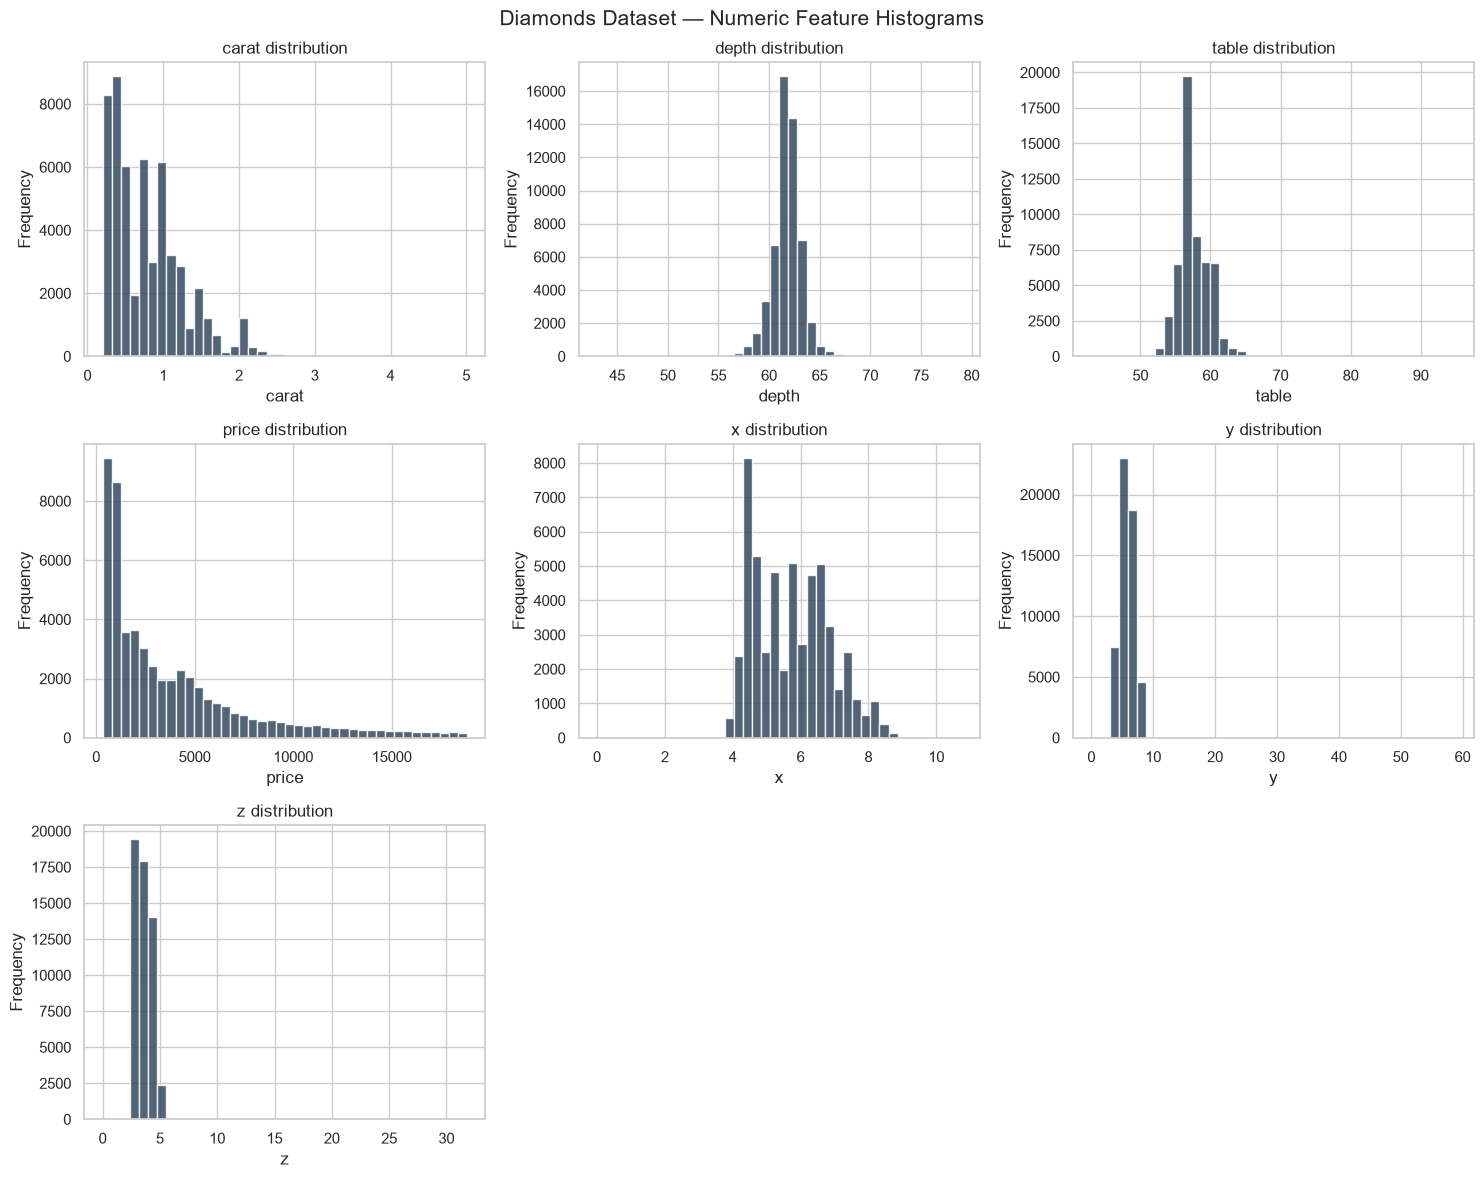

Figure saved: exp02_histograms.png


In [3]:
numeric_cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=40, edgecolor='white', color='#34495e', alpha=0.85)
    axes[i].set_title(f'{col} distribution', fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Diamonds Dataset — Numeric Feature Histograms', fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp02_histograms.png', dpi=150)
plt.show()
print('Figure saved: exp02_histograms.png')

## 3. Box plots — diamond price grouped by cut quality

C:\Users\Omkar\AppData\Local\Temp\ipykernel_17476\3714325267.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='cut', y='price', order=cut_order, palette='Set2', ax=ax)


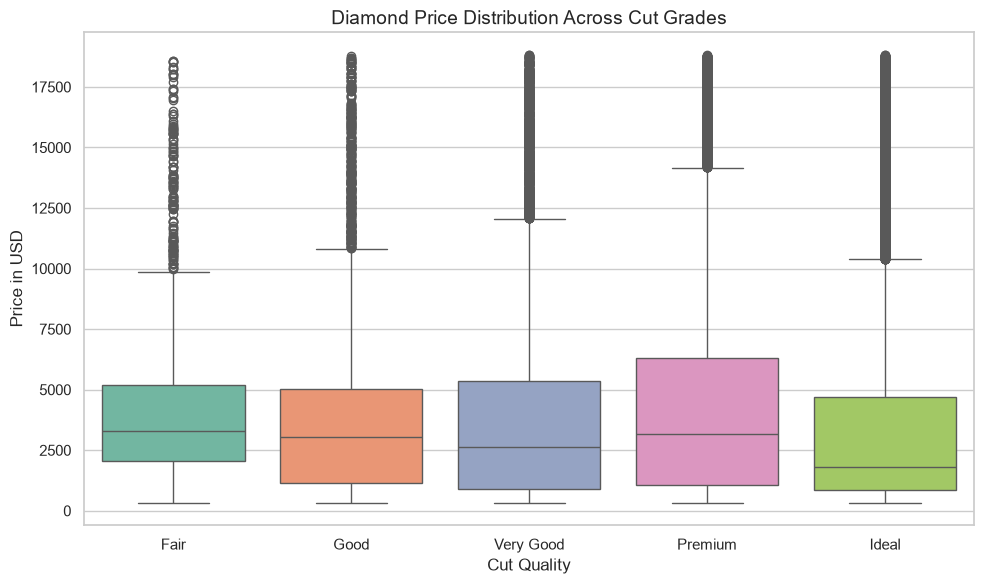

Figure saved: exp02_boxplots.png


In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
sns.boxplot(data=df, x='cut', y='price', order=cut_order, palette='Set2', ax=ax)
ax.set_title('Diamond Price Distribution Across Cut Grades', fontsize=14)
ax.set_xlabel('Cut Quality')
ax.set_ylabel('Price in USD')
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp02_boxplots.png', dpi=150)
plt.show()
print('Figure saved: exp02_boxplots.png')

## 4. Scatter plot — carat weight vs. price stratified by cut

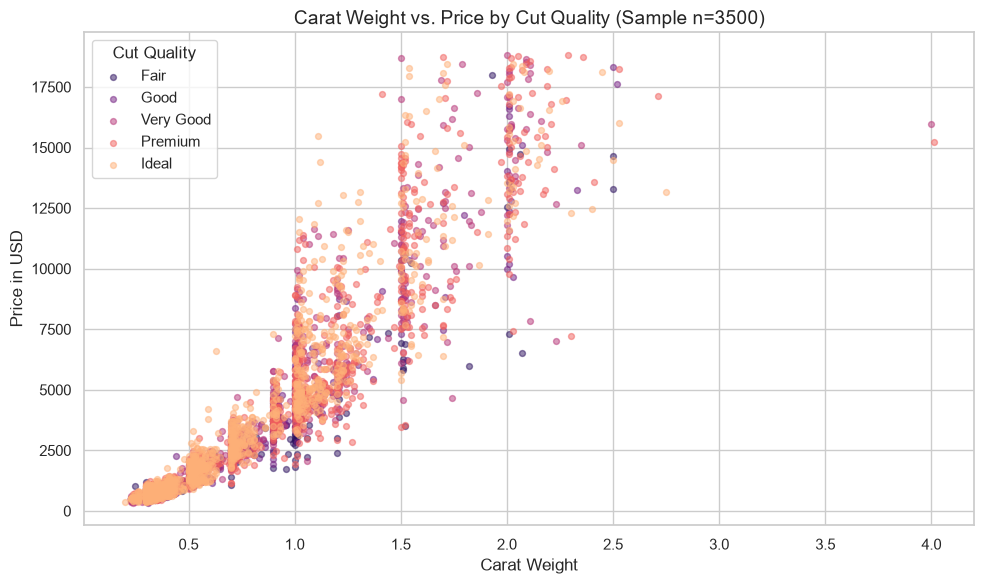

Figure saved: exp02_petal_scatter.png


In [5]:
sample = df.sample(3500, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(10, 6))
palette = sns.color_palette('magma', n_colors=len(cut_order))

for color, cut in zip(palette, cut_order):
    sub = sample[sample['cut'] == cut]
    ax.scatter(sub['carat'], sub['price'], c=[color], label=cut, alpha=0.5, s=18)

ax.set_title('Carat Weight vs. Price by Cut Quality (Sample n=3500)', fontsize=14)
ax.set_xlabel('Carat Weight')
ax.set_ylabel('Price in USD')
ax.legend(title='Cut Quality')
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp02_petal_scatter.png', dpi=150)
plt.show()
print('Figure saved: exp02_petal_scatter.png')

## 5. Feature means across categories

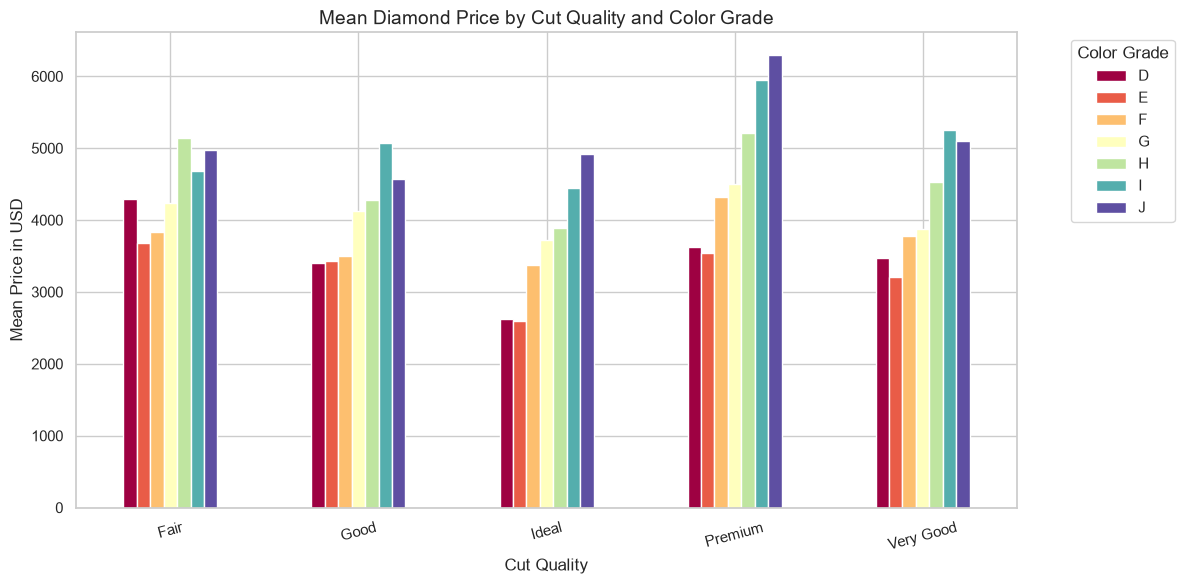

Figure saved: exp02_feature_means.png


In [6]:
pivot = df.groupby(['cut', 'color'])['price'].mean().unstack()
fig, ax = plt.subplots(figsize=(12, 6))
pivot.plot(kind='bar', ax=ax, colormap='Spectral')
ax.set_title('Mean Diamond Price by Cut Quality and Color Grade', fontsize=14)
ax.set_xlabel('Cut Quality')
ax.set_ylabel('Mean Price in USD')
ax.legend(title='Color Grade', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.tick_params(axis='x', rotation=15)
fig.tight_layout()
fig.savefig(FIG_DIR / 'exp02_feature_means.png', dpi=150)
plt.show()
print('Figure saved: exp02_feature_means.png')

## 6. Pair plot — multi-feature interaction

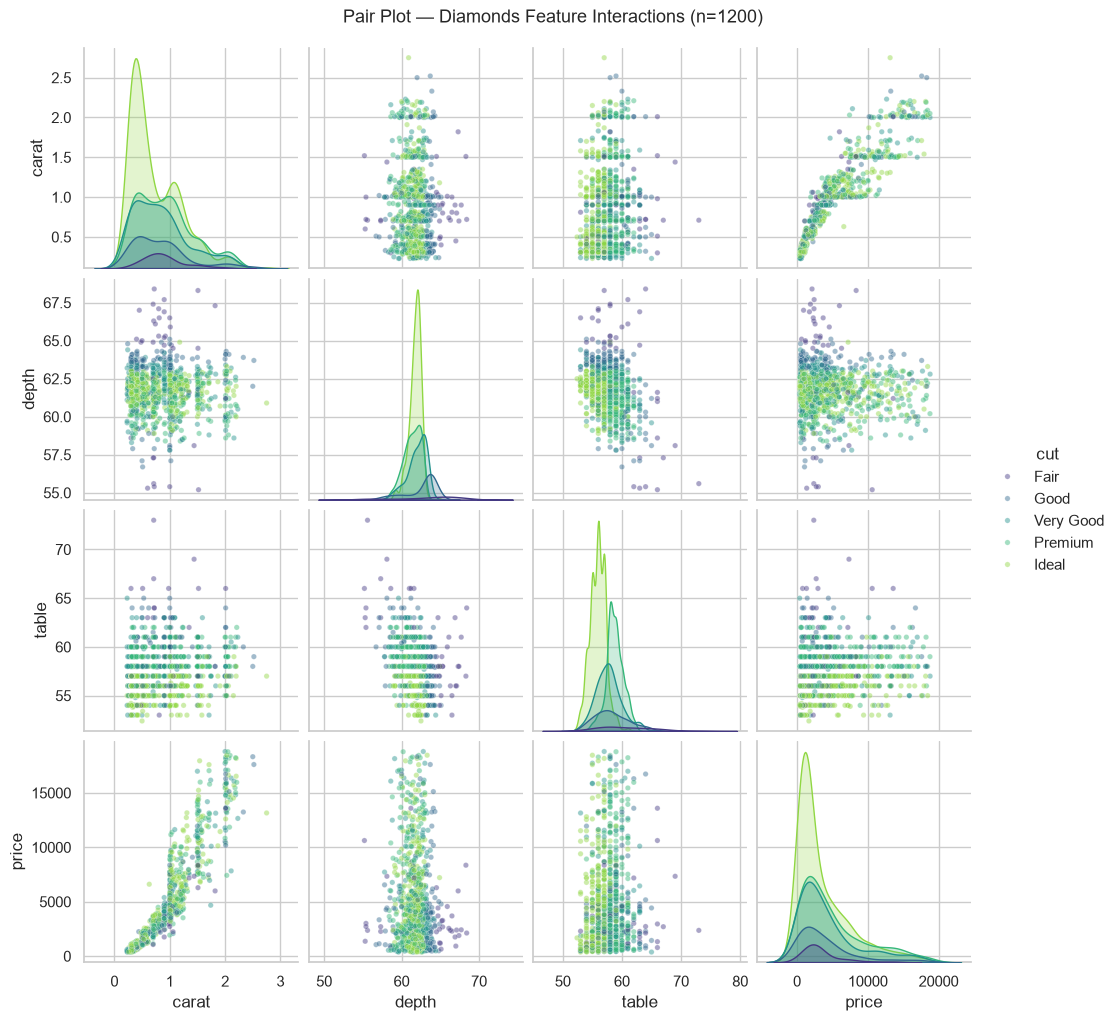

Figure saved: exp02_pairplot.png


In [7]:
sample_small = df.sample(1200, random_state=RANDOM_STATE)
pair_cols = ['carat', 'depth', 'table', 'price']

g = sns.pairplot(sample_small[pair_cols + ['cut']], hue='cut', hue_order=cut_order, palette='viridis', plot_kws={'alpha': 0.45, 's': 15})
g.figure.suptitle('Pair Plot — Diamonds Feature Interactions (n=1200)', y=1.02, fontsize=13)
g.figure.savefig(FIG_DIR / 'exp02_pairplot.png', dpi=120, bbox_inches='tight')
plt.show()
print('Figure saved: exp02_pairplot.png')

## 7. Observations and Result

**Observations:**
- Diamond price exhibits severe positive skewness: majority under \$5,000, but reaching \$18,823.
- Carat weight is non-linearly associated with price, representing the single dominant predictor.
- Fair cut diamonds show an unexpectedly high average price because lower-cut gems in the dataset tend to have larger carat weights.
- Pairplot interactions indicate tight collinearity between carat, x, y, and z dimensions.

**Result:** Multiple visualizations were constructed on the Kaggle Diamonds dataset. Histograms, boxplots, scatter plots, feature mean bars, and pair plots were produced and saved to `outputs/figures/`.